In [2]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('train_barcode.csv')
data = data.set_index('Sample')

target = data.loc[:, "Species"]
target = target.replace({"Pk": 1, "Pv": 0}).astype(int) 
data_predictors = data.loc[:, data.columns != 'Species']

/tmp/ipykernel_450/2578482164.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  target = target.replace({"Pk": 1, "Pv": 0}).astype(int)


In [4]:
test_data = pd.read_csv('test_barcode.csv')
test_data = test_data.set_index('Sample')

y_test = test_data.loc[:, "Species"]
y_test = y_test.replace({"Pk": 1, "Pv": 0}).astype(int) 
x_test = test_data.loc[:, test_data.columns != 'Species']

/tmp/ipykernel_450/1357762790.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test = y_test.replace({"Pk": 1, "Pv": 0}).astype(int)


In [5]:
def svm_test(features):
    grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"),
                        {"C": [0.01, 0.1, 1, 10, 100],
                         "gamma": ["scale", 0.001, 0.01, 0.1, 1]},
                        cv=inner, scoring="f1")         
    grid.fit(data_predictors[features], target)       
    y_pred = grid.predict(x_test[features])   
    score = f1_score(y_test, y_pred)     
    return score

In [6]:
mrmr_barcode_scores = {}

barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

for length in barcode_lengths: 
    with open(f"MRMR_subsets/top_{length}_MRMR") as f:
        features = f.read().splitlines()
    score = svm_test(features)
    mrmr_barcode_scores[length] = score

In [7]:
moremore = []
for length in barcode_lengths: 
    qual = mrmr_barcode_scores[length]
    moremore.append(qual)
    
moremore

[0.9841269841269841, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [8]:
gb_barcode_scores = {}

for length in barcode_lengths: 
    with open(f"GB_subsets/top_{length}_GB.txt") as f:
        features = f.read().splitlines()
    score = svm_test(features)
    gb_barcode_scores[length] = score 

In [9]:
greatb = []
for length in barcode_lengths: 
    qual = gb_barcode_scores[length]
    greatb.append(qual)
    
greatb

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [10]:
ga_barcode_scores = {}

for length in barcode_lengths: 
    with open(f"GA_subsets/top_{length}_GA.txt") as f:
        features = f.read().splitlines()
    score = svm_test(features)
    ga_barcode_scores[length] = score 

In [11]:
goona = []
for length in barcode_lengths: 
    qual = ga_barcode_scores[length]
    goona.append(qual)
    
goona

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

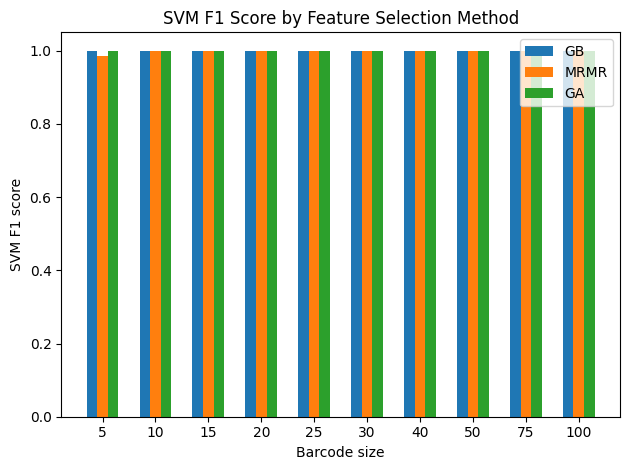

In [13]:
# Bar positions and width
x = np.arange(len(barcode_lengths))
width = 0.2

# Plot bars
plt.bar(x - width, gb_barcode_scores.values(), width, label='GB')
plt.bar(x, mrmr_barcode_scores.values(), width, label='MRMR')
plt.bar(x + width, ga_barcode_scores.values(), width, label='GA')

# Labels and formatting
plt.xlabel('Barcode size')
plt.ylabel('SVM F1 score')
plt.title('SVM F1 Score by Feature Selection Method')
plt.xticks(x, barcode_lengths)
plt.legend()
plt.tight_layout()

plt.savefig('SVM_scores')